# JERICHON — AFML Experiment 01: Label Uniqueness и Sample Weights

**Цель:** проверить одну из наиболее релевантных методик *Advances in Financial Machine Learning*: uniqueness-aware sample weights для перекрывающихся Triple Barrier events.

Сравниваются две модели CatBoost на одинаковых 474 признаках, одинаковых purged expanding walk-forward folds и одинаковых правилах исполнения: (A) обычное обучение; (B) обучение с весами средней уникальности событий. Метки `TIME` исключаются как в текущем baseline.

Подготовка локальных данных, построение Dollar Bars, 73 base + 401 Super Candle features, temporal availability audit и Triple Barrier labels сохраняются из актуального `JERICHON_mark.63.7(3).ipynb`. Сетевые запросы не выполняются.

**Важно:** веса рассчитываются отдельно внутри каждого train fold, только по train-событиям; validation-события не участвуют в вычислении concurrency. Все сравнения используют одинаковые фолды и издержки. Результат исследовательский, не доказательство прибыльности.


## 1. Подготовка данных

Подготовительная часть сохранена из актуального notebook: локальная история AlgoPack → Dollar Bars → 73 base + 401 Super Candle feature → causal availability audit → CUSUM + Triple Barrier.

После этой части запускается отдельный AFML-эксперимент. Старый regime sweep не выполняется.


In [3]:
\
# 0. CONFIG + IMPORTS
from pathlib import Path
import os, sys, inspect, warnings, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplcyberpunk
plt.style.use("cyberpunk")
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, log_loss, brier_score_loss, roc_auc_score,)
from catboost import CatBoostClassifier

TICKER = "SMLT"
DOLLAR_THRESHOLD = 10_000_000
MSK = "Europe/Moscow"
CUSUM_THRESHOLD = 0.001
PT_SL = (1.0, 1.0)
VERTICAL_HORIZON = 50
TARGET_WINDOW = 55
EXPECTED_FEATURES = 474

# Автоматически ищем корень репозитория JERICHON, не фиксируем путь конкретного пользователя.
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную."
    )

ROOT = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data")
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
HISTORY_ROOT = ROOT / "for_ml" / "storage" / "history"

from src.data.builders.dollar_bars import InformationDrivenBars
from src.data.builders.micro_features import MicroFeatures
from src.data.builders.build_features import FeatureBuilder
from src.data.builders import jerichon_feature_pipeline as jfp
from src.backtesting.backtest_engine import BacktestConfig

print("Ticker       :", TICKER)
print("Data root    :", ROOT)
print("History root :", HISTORY_ROOT)
print("Pipeline     :", Path(inspect.getfile(jfp)).resolve())
print("Pipeline API :", [n for n in (
    "build_feature_dataset", "build_dollar_bars_from_trades", "_base",
    "_build_sc_features", "_choose_availability", "_attach_source"
) if hasattr(jfp, n)])


Ticker       : SMLT
Data root    : C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data
History root : C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline     : C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Pipeline API : ['build_feature_dataset', 'build_dollar_bars_from_trades', '_base', '_build_sc_features', '_choose_availability', '_attach_source']


## 1. Загрузка локальной истории

Формат путей сохранён **как в `jerichon_mark_63(3).ipynb`**:

- `data/for_ml/storage/history/realtime/{TICKER}/{YYYY-MM-DD}/trades.parquet`
- `data/for_ml/storage/history/supercandles/{TICKER}/{YYYY-MM-DD}/{tradestats,obstats,orderstats}.parquet`

Файлы только читаются. Если какой-то источник отсутствует, notebook покажет это явно.

In [4]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)

    if not dates:
        raise FileNotFoundError(f"Для {ticker} не найдены сохранённые даты в {history_root}")

    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    print(f"Saved dates discovered: {len(dates)}")
    print(f"Date range            : {dates[0]} → {dates[-1]}")
    print("\\nLocal rows:")
    display(pd.DataFrame({"source": list(out), "rows": [len(out[k]) for k in out]}))
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"Не хватает локальных источников: {missing}. API-запрос не будет выполняться.")
    return out, dates

data, SAVED_DATES = load_local_history(HISTORY_ROOT, TICKER)

Saved dates discovered: 12
Date range            : 2026-09-25 → 2026-10-15
\nLocal rows:


,source,rows
0,candles,10698
1,trades,562271
2,orderbook,240
3,tradestats,2154
4,obstats,2094
5,orderstats,2166


## 2. Построение Dollar Bars и 474 признаков

Используем подготовленный модуль `jerichon_feature_pipeline.py`, а не копируем его инженерный код в notebook. Важно: **не вызываем** публичный `build_feature_dataset()`, если он сам создаёт `AlgoPackProvider`; вместо этого вызываем локальные функции модуля над уже прочитанными DataFrame.

Если локальная версия модуля не содержит ожидаемые helper-функции, выполнение остановится с понятной ошибкой, а не отправит запрос в API.

In [5]:
# Сначала проверяем интерфейс установленного файла — никаких сетевых вызовов здесь нет.
required_helpers = (
    "_trades_for_bars",
    "build_dollar_bars_from_trades",
    "_base",
    "_build_sc_features",
    "_choose_availability",
    "_attach_source",
)
missing_helpers = [name for name in required_helpers if not hasattr(jfp, name)]
if missing_helpers:
    raise RuntimeError(
        "В установленном jerichon_feature_pipeline.py не найдены helper-функции: "
        f"{missing_helpers}. Проверь, что в проекте стоит актуальная версия pipeline. "
        "Этот notebook намеренно не переключается на API."
    )

print("Helper signatures:")
for name in required_helpers:
    print(f"  {name}{inspect.signature(getattr(jfp, name))}")

Helper signatures:
  _trades_for_bars(trades)
  build_dollar_bars_from_trades(trades, threshold=13000000)
  _base(bars)
  _build_sc_features(raw_sources, bars_for_features)
  _choose_availability(df, source_name)
  _attach_source(bars, feature_frame, raw_source, source)


In [6]:
# Dollar Bars: используем тот же денежный объём VALUE / PRICE, что и в reference.
bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
if bars is None or bars.empty:
    raise RuntimeError("Dollar Bar builder вернул пустой результат.")

# Унифицируем имя времени для последующих causal joins.
if "bar_ts" not in bars.columns:
    if "close_time" not in bars.columns:
        raise RuntimeError(f"В bars нет bar_ts/close_time. Колонки: {list(bars.columns)}")
    bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
else:
    bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)

bars = (bars.dropna(subset=["bar_ts"])
             .sort_values("bar_ts")
             .drop_duplicates("bar_ts", keep="last")
             .reset_index(drop=True))

print("Dollar Bars:", len(bars))
print("Period:", bars["bar_ts"].min(), "→", bars["bar_ts"].max())
display(bars.head(3))

Dollar Bars: 2488
Period: 2026-09-25 04:03:05+00:00 → 2026-10-15 20:36:12+00:00


,open,high,low,close,volume,value,count,open_time,close_time,bar_ts
0,251.2,252.2,251.0,252.2,40061.0,10074986.8,213,2026-09-25 03:59:54+00:00,2026-09-25 04:03:05+00:00,2026-09-25 04:03:05+00:00
1,252.0,252.2,251.0,251.6,40151.0,10095285.8,250,2026-09-25 04:03:05+00:00,2026-09-25 04:16:20+00:00,2026-09-25 04:16:20+00:00
2,251.6,251.8,250.6,251.0,39792.0,10000099.6,274,2026-09-25 04:16:20+00:00,2026-09-25 04:33:18+00:00,2026-09-25 04:33:18+00:00


In [7]:
# Base 73 + Super Candle 401. Работаем через helper-функции pipeline.
base_raw = jfp._base(bars.copy())
if isinstance(base_raw, tuple):
    # Поддержка версий helper, возвращающих (features, metadata).
    base_raw = base_raw[0]
if not isinstance(base_raw, pd.DataFrame):
    raise TypeError(f"_base должен вернуть DataFrame, получено: {type(base_raw)}")

# Приводим base frame к контракту bar_ts + 73 числовых признака.
if "bar_ts" not in base_raw.columns:
    if "close_time" in base_raw.columns:
        base_raw = base_raw.rename(columns={"close_time": "bar_ts"})
    elif isinstance(base_raw.index, pd.DatetimeIndex):
        base_raw = base_raw.reset_index().rename(columns={base_raw.index.name or "index": "bar_ts"})
    elif "ts" in base_raw.columns:
        base_raw = base_raw.rename(columns={"ts": "bar_ts"})
    else:
        raise RuntimeError(f"Не найден временной ключ в _base output. Колонки: {list(base_raw.columns)[:25]}")

base_raw["bar_ts"] = pd.to_datetime(base_raw["bar_ts"], errors="coerce", utc=True)
base_raw = base_raw.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

# _build_sc_features может возвращать feature_frames либо (feature_frames, groups).
# Адаптируем Dollar Bars к формату, ожидаемому pipeline.
bars_for_sc = bars.copy()

# В pipeline ожидаются ts и CLOSE.
if "ts" not in bars_for_sc.columns:
    if "bar_ts" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["bar_ts"]
    elif "close_time" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["close_time"]
    else:
        raise KeyError("В bars отсутствует временная колонка ts/bar_ts/close_time")

if "CLOSE" not in bars_for_sc.columns:
    if "close" in bars_for_sc.columns:
        bars_for_sc["CLOSE"] = bars_for_sc["close"]
    else:
        raise KeyError("В bars отсутствует цена закрытия CLOSE/close")

bars_for_sc["ts"] = pd.to_datetime(bars_for_sc["ts"], errors="coerce", utc=True)

bars_for_sc = (
    bars_for_sc.dropna(subset=["ts"])
    .sort_values("ts")
    .reset_index(drop=True))

sc_result = jfp._build_sc_features(data, bars_for_sc)

if isinstance(sc_result, tuple):
    feature_frames = sc_result[0]
    feature_groups = sc_result[1] if len(sc_result) > 1 else {}
else:
    feature_frames = sc_result
    feature_groups = {}

if not isinstance(feature_frames, dict):
    raise TypeError("_build_sc_features должен возвращать dict feature frames.")

print("Base output shape:", base_raw.shape)
print("Super Candle feature groups:", list(feature_frames))

Base output shape: (2488, 74)
Super Candle feature groups: ['tradestats', 'orderstats', 'obstats']


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

In [8]:
# Availability validation and causal joins, source by source.
# Helpers' outputs are inspected to support the current prepared module contract.
validated = {}
availability_diagnostics = []

for source in ("tradestats", "obstats", "orderstats"):
    if data[source].empty:
        raise RuntimeError(f"Локальный источник {source} пуст.")

    result = jfp._choose_availability(data[source].copy(), source)
    if isinstance(result, tuple):
        validated[source] = result[0]
        if len(result) > 1 and isinstance(result[1], pd.DataFrame):
            availability_diagnostics.append(result[1])
    else:
        validated[source] = result

print("Validated sources:")
for source, frame in validated.items():
    print(f"  {source:12s}: {len(frame):,} rows, columns={len(frame.columns)}")

if availability_diagnostics:
    display(pd.concat(availability_diagnostics, ignore_index=True))

Validated sources:
  tradestats  : 2,154 rows, columns=2
  obstats     : 2,094 rows, columns=2
  orderstats  : 2,166 rows, columns=2


In [9]:
# Normalize the bars frame for the pipeline's attach helper.
bar_frame = bars.copy()
if "bar_ts" not in bar_frame.columns:
    raise RuntimeError("bar_ts missing from Dollar Bars.")

# Resolve each raw source to the corresponding feature frame by name.
def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source} с feature frame. Доступны: {list(frames)}")

causal = bar_frame.copy()
for source in ("tradestats", "obstats", "orderstats"):
    feature_frame = resolve_feature_frame(source, feature_frames)
    
    # ИСПРАВЛЕНО: правильный порядок аргументов + исходные данные вместо validated
    attached = jfp._attach_source(causal, feature_frame, data[source], source)
    
    # Поддержка helper, возвращающего либо изменённый frame, либо None in-place.
    if isinstance(attached, pd.DataFrame):
        causal = attached
    print(f"{source:12s} attached → {causal.shape}")

# Добавляем base features по точному bar_ts.
base_cols = [c for c in base_raw.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base_raw[c])]
if len(base_cols) != 73:
    raise RuntimeError(f"Ожидалось 73 base features, найдено {len(base_cols)}.")

base_join = base_raw[["bar_ts"] + base_cols].copy()
base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols})
base_cols = [c for c in base_join.columns if c.startswith("base__")]

if "bar_ts" not in causal.columns:
    raise RuntimeError(f"После causal join нет bar_ts. Колонки: {list(causal.columns)[:30]}")

causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
base_join["bar_ts"] = pd.to_datetime(base_join["bar_ts"], errors="coerce", utc=True)
causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

# Identify features and provenance without admitting timestamps into X.
time_cols = {"bar_ts", "bar_ts_utc", "ts", "ts_utc", "close_time"}
provenance_cols = [
    c for c in causal.columns
    if c.endswith("__event_ts") or c.endswith("__available_at")
]
sc_prefixes = ("tradestats__", "obstats__", "orderstats__")
sc_feature_cols = [
    c for c in causal.columns
    if c.startswith(sc_prefixes)
    and c not in provenance_cols
    and pd.api.types.is_numeric_dtype(causal[c])
]
# Не включаем сырые OHLCV/служебные колонки из bars: только канонические 73 + 401.
feature_cols = base_cols + sc_feature_cols

if len(feature_cols) != EXPECTED_FEATURES:
    raise RuntimeError(
        f"Feature inventory mismatch: {len(feature_cols)} numeric ML features, expected {EXPECTED_FEATURES}. "
        "Не продолжаем обучение на непроверенной матрице."
    )

if len(feature_cols) != len(set(feature_cols)):
    raise RuntimeError("Есть дублирующиеся имена признаков.")

FINAL_DATASET = causal[["bar_ts"] + feature_cols + provenance_cols].copy()
FINAL_DATASET = FINAL_DATASET.sort_values("bar_ts").reset_index(drop=True)
X_raw = FINAL_DATASET[feature_cols].copy()

print("FINAL_DATASET:", FINAL_DATASET.shape)
print("Rows:", len(FINAL_DATASET))
print("ML features:", len(feature_cols))
print("Provenance columns:", len(provenance_cols))

tradestats   attached → (2488, 106)
obstats      attached → (2488, 244)
orderstats   attached → (2488, 417)
FINAL_DATASET: (2488, 481)
Rows: 2488
ML features: 474
Provenance columns: 6


## 3. Temporal audit

Проверяем `available_at <= bar_ts` и `event_ts <= bar_ts` для каждого источника. Признаки из будущего — блокирующая ошибка. Дубликаты/пропуски/бесконечности дальше рассматриваются отдельно.

In [10]:
temporal_rows = []
for source in ("tradestats", "obstats", "orderstats"):
    av_col = f"{source}__available_at"
    ev_col = f"{source}__event_ts"
    if av_col not in FINAL_DATASET.columns or ev_col not in FINAL_DATASET.columns:
        raise RuntimeError(f"Нет provenance для {source}: ожидались {av_col}, {ev_col}")

    av = pd.to_datetime(FINAL_DATASET[av_col], errors="coerce", utc=True)
    ev = pd.to_datetime(FINAL_DATASET[ev_col], errors="coerce", utc=True)
    bar_ts = pd.to_datetime(FINAL_DATASET["bar_ts"], errors="coerce", utc=True)

    bad_av = av.notna() & (av > bar_ts)
    bad_ev = ev.notna() & (ev > bar_ts)
    temporal_rows.append({
        "source": source,
        "bars": len(FINAL_DATASET),
        "availability_future_violations": int(bad_av.sum()),
        "event_future_violations": int(bad_ev.sum()),
        "availability_missing_pct": round(float(av.isna().mean() * 100), 3),
        "event_missing_pct": round(float(ev.isna().mean() * 100), 3),
    })

temporal_audit = pd.DataFrame(temporal_rows)
display(temporal_audit)

if temporal_audit[["availability_future_violations", "event_future_violations"]].to_numpy().sum() != 0:
    raise RuntimeError("TEMPORAL AUDIT FAILED: обнаружен look-ahead по provenance.")
print("TEMPORAL AUDIT: PASS")

,source,bars,availability_future_violations,event_future_violations,availability_missing_pct,event_missing_pct
0,tradestats,2488,0,0,0.00,0.00
1,obstats,2488,0,0,0.04,0.04
2,orderstats,2488,0,0,0.00,0.00


TEMPORAL AUDIT: PASS


## 4. Проверка качества признаков

Нулевые значения не удаляем автоматически. Важные показатели:
- `NaN` и `±inf` по каждому признаку;
- доля нулей (диагностика, не критерий удаления);
- константные признаки;
- полностью пустые признаки;
- дублирующиеся строки и timestamps.

Исходный `FINAL_DATASET` не перезаписывается. Для модели создаётся отдельная копия, в которой бесконечности переводятся в `NaN`; далее imputer обучается только на train.

In [11]:
X_num = X_raw.apply(pd.to_numeric, errors="coerce")
arr = X_num.to_numpy(dtype="float64", copy=True)
finite_mask = np.isfinite(arr)

quality = pd.DataFrame(index=X_num.columns)
quality["missing_pct"] = X_num.isna().mean() * 100
quality["positive_inf"] = np.isposinf(arr).sum(axis=0)
quality["negative_inf"] = np.isneginf(arr).sum(axis=0)
quality["zero_pct"] = (X_num.eq(0).mean() * 100)
quality["unique_values"] = X_num.nunique(dropna=True)
quality["all_missing"] = X_num.isna().all()
quality["constant_or_single_value"] = quality["unique_values"] <= 1
quality["non_finite_total"] = quality["positive_inf"] + quality["negative_inf"]

print("Rows:", len(X_num), "| features:", X_num.shape[1])
print("NaN cells:", int(X_num.isna().sum().sum()))
print("+inf cells:", int(np.isposinf(arr).sum()))
print("-inf cells:", int(np.isneginf(arr).sum()))
print("Zero cells (% of all feature cells):", round(float(X_num.eq(0).to_numpy().mean() * 100), 2))
print("Duplicate bar_ts:", int(FINAL_DATASET["bar_ts"].duplicated().sum()))
print("Duplicate feature rows:", int(X_num.duplicated().sum()))

print("\\nWorst missingness:")
display(quality.sort_values(["missing_pct", "non_finite_total"], ascending=False).head(30))

print("\\nFeatures with infinities:")
display(quality.loc[quality["non_finite_total"] > 0].sort_values("non_finite_total", ascending=False))

print("\\nConstant / all-missing features:")
display(quality.loc[quality["constant_or_single_value"] | quality["all_missing"]])

Rows: 2488 | features: 474
NaN cells: 1335
+inf cells: 0
-inf cells: 0
Zero cells (% of all feature cells): 0.93
Duplicate bar_ts: 0
Duplicate feature rows: 0
\nWorst missingness:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total
tradestats__ts_flow_x_return_ret,16.800643,0,0,0.000000,745,False,False,0
tradestats__ts_vwap_b_s_bps_ret,15.032154,0,0,2.853698,843,False,False,0
obstats__ob_val_imb_bbo_vs_deep_ret,2.210611,0,0,1.004823,923,False,False,0
obstats__ob_vol_imb_bbo_vs_deep_ret,1.607717,0,0,0.964630,888,False,False,0
tradestats__ts_trade_imbalance_ret,0.482315,0,0,0.000000,1113,False,False,0
orderstats__os_put_vwap_b_s_bps_ret,0.482315,0,0,0.000000,1120,False,False,0
orderstats__os_put_orders_imb_ret,0.442122,0,0,0.000000,1120,False,False,0
tradestats__ts_vwap_b_s_bps_chg,0.200965,0,0,3.577170,1053,False,False,0
tradestats__ts_vwap_b_s_bps_z3,0.200965,0,0,0.321543,1118,False,False,0
tradestats__ts_vwap_b_s_bps_ma3,0.200965,0,0,0.080386,1114,False,False,0


\nFeatures with infinities:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


\nConstant / all-missing features:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


In [12]:
# Separate ML copy: keep source dataset unchanged.
X_model = X_num.replace([np.inf, -np.inf], np.nan).copy()

# Remove only features that cannot carry information at all (all missing or constant).
drop_features = quality.index[quality["all_missing"] | quality["constant_or_single_value"]].tolist()
if drop_features:
    print("Removing non-informative columns from model copy:", len(drop_features))
    print(drop_features[:30])
    X_model = X_model.drop(columns=drop_features)

print("X_model shape:", X_model.shape)
print("Remaining NaN cells (to be handled by train-only imputer):", int(X_model.isna().sum().sum()))

# Optional strict stop for pathological data; does not delete rows.
if X_model.shape[1] == 0:
    raise RuntimeError("После удаления пустых/константных признаков не осталось признаков.")

X_model shape: (2488, 474)
Remaining NaN cells (to be handled by train-only imputer): 1335


## 5. CUSUM + Triple Barrier: бинарная цель UP/DOWN

Triple Barrier по-прежнему строит три исходные метки, чтобы диагностировать распределение событий:
- `+1` — первым достигнут верхний барьер (`UP`);
- `-1` — первым достигнут нижний барьер (`DOWN`);
- `0` — до вертикального барьера не достигнут ни один горизонтальный барьер (`TIME`).

**В модель `TIME` не попадает вообще.** После визуализации распределения остаются только события `UP` и `DOWN`, а целевая переменная кодируется как `DOWN=0`, `UP=1`. Train/holdout делятся хронологически, пересекающие границу исходы purged.

CUSUM + TRIPLE BARRIER
CUSUM threshold : 0.001
PT_SL           : (1.0, 1.0) (TP multiplier, SL multiplier)
Vertical horizon: 50 Dollar Bars
Target window   : 55
CUSUM events    : 1,607
Triple Barrier events: 1,606
Raw labels: -1=DOWN, 0=TIME, +1=UP
  DOWN :     819 ( 51.00%)
  TIME :       1 (  0.06%)
  UP   :     786 ( 48.94%)


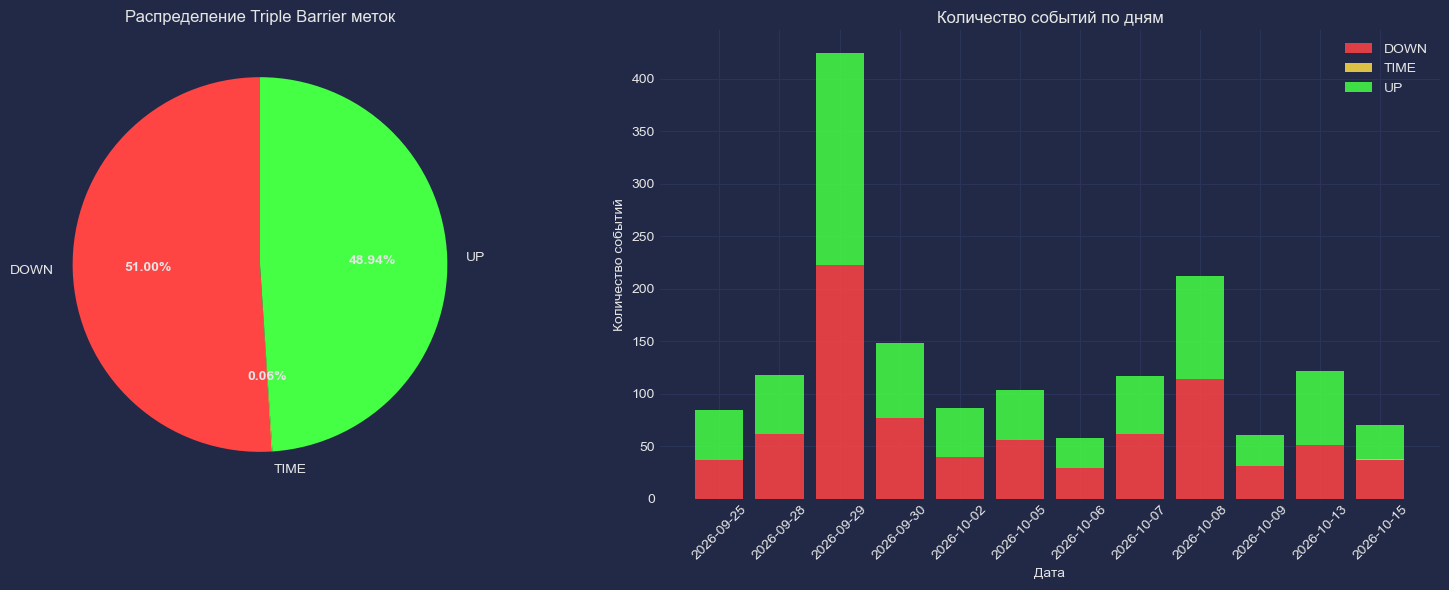


Aligned events before excluding TIME: 1,606
label
-1    819
 0      1
 1    786
Name: count, dtype: int64


In [13]:
# =============================================================================
# LABELS: CUSUM → TRIPLE BARRIER → EVENT-ALIGNED X/y → BINARY TARGET
# =============================================================================
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling

# Use exactly the Dollar Bars that produced FINAL_DATASET.
bars_for_labeling = bars.copy()
if "bar_ts" not in bars_for_labeling.columns:
    raise RuntimeError(f"В bars отсутствует bar_ts. Колонки: {list(bars_for_labeling.columns)}")

rename_map = {
    "open": "OPEN", "high": "HIGH", "low": "LOW", "close": "CLOSE",
    "OPEN": "OPEN", "HIGH": "HIGH", "LOW": "LOW", "CLOSE": "CLOSE",
}
bars_for_labeling = bars_for_labeling.rename(columns=rename_map)
required_ohlc = ["HIGH", "LOW", "CLOSE"]
missing_ohlc = [c for c in required_ohlc if c not in bars_for_labeling.columns]
if missing_ohlc:
    raise RuntimeError(f"Для Triple Barrier не хватает OHLC-колонок: {missing_ohlc}")

bars_for_labeling["bar_ts"] = pd.to_datetime(
    bars_for_labeling["bar_ts"], errors="coerce", utc=True
)
bars_for_labeling = (
    bars_for_labeling.dropna(subset=["bar_ts"] + required_ohlc)
    .sort_values("bar_ts")
    .drop_duplicates("bar_ts", keep="last")
    .set_index("bar_ts")
)
bars_for_labeling.index.name = "bar_ts"

events_idx = cusum_filter(
    bars_for_labeling["CLOSE"].astype(float),
    threshold=CUSUM_THRESHOLD,
)
events_idx = pd.DatetimeIndex(events_idx)
events_idx = events_idx[events_idx.isin(bars_for_labeling.index)]
events_idx = events_idx.drop_duplicates().sort_values()

print("=" * 80)
print("CUSUM + TRIPLE BARRIER")
print("=" * 80)
print(f"CUSUM threshold : {CUSUM_THRESHOLD}")
print(f"PT_SL           : {PT_SL} (TP multiplier, SL multiplier)")
print(f"Vertical horizon: {VERTICAL_HORIZON} Dollar Bars")
print(f"Target window   : {TARGET_WINDOW}")
print(f"CUSUM events    : {len(events_idx):,}")
if len(events_idx) == 0:
    raise RuntimeError("CUSUM не нашёл событий. Проверь CUSUM_THRESHOLD и входные бары.")

labeled_all = triple_barrier_labeling(
    bars=bars_for_labeling,
    events=events_idx,
    pt_sl=PT_SL,
    vertical_barrier=VERTICAL_HORIZON,
    target_window=TARGET_WINDOW,
    target_method="ewm",
)
if labeled_all is None or labeled_all.empty:
    raise RuntimeError("Triple Barrier вернул пустую таблицу меток.")
if not {"label", "t1"}.issubset(labeled_all.columns):
    raise RuntimeError(
        "Ожидались колонки label и t1; получены: "
        f"{list(labeled_all.columns)}"
    )

labeled_all.index = pd.to_datetime(labeled_all.index, errors="coerce", utc=True)
labeled_all = labeled_all[~labeled_all.index.isna()].sort_index()
labeled_all = labeled_all[labeled_all["label"].isin([-1, 0, 1])].copy()
labeled_all["label"] = labeled_all["label"].astype(int)
labeled_all["t1"] = pd.to_datetime(labeled_all["t1"], errors="coerce", utc=True)

print(f"Triple Barrier events: {len(labeled_all):,}")
print("Raw labels: -1=DOWN, 0=TIME, +1=UP")
label_counts = labeled_all["label"].value_counts().reindex([-1, 0, 1], fill_value=0)
for value, name in [(-1, "DOWN"), (0, "TIME"), (1, "UP")]:
    count = int(label_counts.loc[value])
    pct = 100 * count / len(labeled_all) if len(labeled_all) else 0
    print(f"  {name:5s}: {count:7,d} ({pct:6.2f}%)")

# Visual diagnostics include TIME so we can see how often the vertical barrier wins.
label_names = {-1: "DOWN", 0: "TIME", 1: "UP"}
label_colors = {-1: "#ff4444", 0: "#ffdd44", 1: "#44ff44"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_counts = [int(label_counts.loc[v]) for v in (-1, 0, 1)]
if sum(plot_counts):
    _, _, autotexts = axes[0].pie(
        plot_counts,
        labels=[label_names[v] for v in (-1, 0, 1)],
        colors=[label_colors[v] for v in (-1, 0, 1)],
        autopct="%1.2f%%",
        startangle=90,
    )
    for t in autotexts:
        t.set_fontsize(10)
        t.set_fontweight("bold")
axes[0].set_title("Распределение Triple Barrier меток")

plot_labels = pd.DataFrame({
    "day": pd.DatetimeIndex(labeled_all.index).date,
    "label": labeled_all["label"].to_numpy(),
})
daily_counts = (
    plot_labels.groupby(["day", "label"]).size()
    .unstack(fill_value=0)
    .reindex(columns=[-1, 0, 1], fill_value=0)
    .sort_index()
)
bottom = np.zeros(len(daily_counts), dtype=float)
for cls in (-1, 0, 1):
    vals = daily_counts[cls].to_numpy()
    axes[1].bar(
        daily_counts.index.astype(str), vals, bottom=bottom,
        label=label_names[cls], color=label_colors[cls], alpha=0.85,
    )
    bottom += vals
axes[1].set_title("Количество событий по дням")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Количество событий")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

# Event-aligned X/y. One concat avoids pandas' highly-fragmented DataFrame warning.
if len(FINAL_DATASET) != len(X_model):
    raise RuntimeError(
        f"FINAL_DATASET и X_model имеют разную длину: {len(FINAL_DATASET)} vs {len(X_model)}"
    )
model_feature_cols = list(X_model.columns)
feature_table = pd.concat(
    [FINAL_DATASET[["bar_ts"]].reset_index(drop=True),
     X_model.reset_index(drop=True)],
    axis=1,
)
feature_table["bar_ts"] = pd.to_datetime(feature_table["bar_ts"], errors="coerce", utc=True)
feature_table = feature_table.dropna(subset=["bar_ts"]).set_index("bar_ts").sort_index()

X_all_raw = feature_table.reindex(labeled_all.index)[model_feature_cols].copy()
y_all_raw = labeled_all["label"].reindex(X_all_raw.index)
aligned = y_all_raw.notna() & X_all_raw.index.notna()
X_all_raw = X_all_raw.loc[aligned].copy()
y_all_raw = y_all_raw.loc[aligned].astype(int)
labeled_all = labeled_all.reindex(X_all_raw.index)

if not X_all_raw.index.equals(y_all_raw.index):
    raise RuntimeError("X/y event indices are not aligned.")
if X_all_raw.index.has_duplicates:
    raise RuntimeError("Duplicate event timestamps after feature/label alignment.")

print(f"\nAligned events before excluding TIME: {len(X_all_raw):,}")
print(y_all_raw.value_counts().reindex([-1, 0, 1], fill_value=0))

# TIME is not a prediction target. Keep only events where TP or SL won.
directional_mask = y_all_raw.isin([-1, 1])
X_all = X_all_raw.loc[directional_mask].copy()
y_all = y_all_raw.loc[directional_mask].copy()
labeled = labeled_all.reindex(X_all.index).copy()

if set(y_all.unique()) != {-1, 1}:
    raise RuntimeError(f"Ожидались оба directional класса -1/+1; получены {sorted(y_all.unique())}")

# Binary target for CatBoost: DOWN=0, UP=1.
label_map = {-1: 0, 1: 1}
y_binary = y_all.map(label_map).astype(int)

# Chronological 75/25 holdout split. Purge training outcomes reaching holdout start.
if len(X_all) < 100:
    raise RuntimeError(f"Слишком мало directional событий: {len(X_all)}")
split_idx = int(len(X_all) * 0.75)
if split_idx <= 0 or split_idx >= len(X_all):
    raise RuntimeError("Невозможно построить chronological split.")

HOLDOUT_START = X_all.index[split_idx]
train_candidate_index = X_all.index[:split_idx]
test_index = X_all.index[split_idx:]
train_end_times = labeled.reindex(train_candidate_index)["t1"]
train_keep = train_end_times.notna() & (train_end_times < HOLDOUT_START)
train_index = train_candidate_index[train_keep.to_numpy()]



## 2. AFML: event intervals, purged walk-forward folds и label uniqueness

Для события `i` интервал информации — `[t0_i, t1_i]`, где `t0_i` — timestamp события, `t1_i` — окончание Triple Barrier. На каждом баре `t` считаем concurrency `c_t`, то есть число train-событий, чьи интервалы включают этот бар. Уникальность события:

\[
u_i = \frac{1}{|I_i|}\sum_{t \in I_i}\frac{1}{c_t}
\]

Веса нормируются к среднему 1, чтобы их масштаб был сопоставим с обычным обучением. Важно: concurrency и веса рассчитываются только по train-событиям конкретного fold.


In [14]:

SEED = 63
INITIAL_CAPITAL = 100_000.0
COMMISSION = 0.0006
SLIPPAGE = 0.0001
ENTRY_CUTOFF_HOUR = 22
FORCED_CLOSE_HOUR = 23
SESSION_TIMEZONE = "Europe/Moscow"

required_objects = ["bars", "X_all", "y_binary", "labeled", "FINAL_DATASET"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(f"Не хватает объектов из подготовительных ячеек: {missing_objects}")

# Canonicalize timestamps and enforce a single aligned event index.
bars = bars.copy()
bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
bars = (bars.dropna(subset=["bar_ts"]).sort_values("bar_ts")
        .drop_duplicates("bar_ts", keep="last").reset_index(drop=True))
bar_times = pd.DatetimeIndex(bars["bar_ts"])

X_all = X_all.copy()
X_all.index = pd.to_datetime(X_all.index, errors="coerce", utc=True)
y_binary = y_binary.copy()
y_binary.index = pd.to_datetime(y_binary.index, errors="coerce", utc=True)
labeled = labeled.copy()
labeled.index = pd.to_datetime(labeled.index, errors="coerce", utc=True)
labeled["t1"] = pd.to_datetime(labeled["t1"], errors="coerce", utc=True)

common = X_all.index.intersection(y_binary.index).intersection(labeled.index)
X_all, y_binary, labeled = X_all.loc[common].sort_index(), y_binary.loc[common].sort_index(), labeled.loc[common].sort_index()
if X_all.index.has_duplicates or not X_all.index.equals(y_binary.index) or not X_all.index.equals(labeled.index):
    raise RuntimeError("X/y/labels имеют дубли или несовпадающие event timestamps.")
if set(y_binary.dropna().unique()) != {0, 1}:
    raise RuntimeError(f"Ожидались классы DOWN=0, UP=1; получены {sorted(y_binary.dropna().unique())}")
if not {"upper", "lower", "t1"}.issubset(labeled.columns):
    raise RuntimeError("В labeled нужны upper/lower/t1 для backtest event_labels.")

# Same expanding walk-forward boundaries as the preceding research notebook.
n = len(X_all)
fold_specs = [("WF1", 0.50, 0.65), ("WF2", 0.65, 0.80), ("WF3", 0.80, 1.00)]
folds = []
for name, train_frac, val_end_frac in fold_specs:
    train_end_pos = int(n * train_frac)
    val_end_pos = min(n, int(n * val_end_frac))
    train_candidates = X_all.index[:train_end_pos]
    val_idx_all = X_all.index[train_end_pos:val_end_pos]
    if len(val_idx_all) == 0:
        continue
    val_start = val_idx_all[0]
    val_end = X_all.index[val_end_pos] if val_end_pos < n else None

    # Purge any training event whose label interval reaches validation start.
    train_t1 = labeled.loc[train_candidates, "t1"]
    train_idx = train_candidates[(train_t1.notna() & (train_t1 < val_start)).to_numpy()]

    # Validation events must have their complete outcome inside this validation block.
    val_t1 = labeled.loc[val_idx_all, "t1"]
    val_mask = val_t1.notna()
    if val_end is not None:
        val_mask &= val_t1 < val_end
    val_idx = val_idx_all[val_mask.to_numpy()]

    if len(train_idx) < 50 or len(val_idx) < 20:
        warnings.warn(f"{name}: fold слишком мал после purge; train={len(train_idx)}, val={len(val_idx)}")
        continue
    if y_binary.loc[train_idx].nunique() != 2:
        warnings.warn(f"{name}: после purge в train остался один класс; fold пропущен.")
        continue
    folds.append({
        "name": name, "train_idx": train_idx, "val_idx": val_idx,
        "val_start": val_start, "val_end": val_end,
    })

if len(folds) < 2:
    raise RuntimeError(f"Получено только {len(folds)} пригодных walk-forward folds; нужно не менее 2.")

print("Aligned directional events:", len(X_all))
print("Folds:", [(f["name"], len(f["train_idx"]), len(f["val_idx"])) for f in folds])


Aligned directional events: 1605
Folds: [('WF1', 769, 209), ('WF2', 1011, 204), ('WF3', 1247, 321)]


In [15]:

def uniqueness_weights(train_index, event_labels, all_bar_times):
    """AFML-style average uniqueness over train-event intervals only."""
    train_index = pd.DatetimeIndex(train_index)
    if len(train_index) == 0:
        raise ValueError("Нельзя вычислить uniqueness для пустого train.")

    t1 = pd.to_datetime(event_labels.reindex(train_index)["t1"], errors="coerce", utc=True)
    valid = t1.notna()
    train_index = train_index[valid.to_numpy()]
    t1 = t1.loc[train_index]
    if len(train_index) == 0:
        raise ValueError("У всех train events отсутствует t1.")

    bar_ns = pd.DatetimeIndex(all_bar_times).asi8
    start_ns = train_index.asi8
    end_ns = pd.DatetimeIndex(t1).asi8
    starts = np.searchsorted(bar_ns, start_ns, side="left")
    ends = np.searchsorted(bar_ns, end_ns, side="left")

    # Restrict to valid bar range and enforce a non-empty inclusive interval.
    starts = np.clip(starts, 0, len(bar_ns) - 1)
    ends = np.clip(ends, 0, len(bar_ns) - 1)
    ends = np.maximum(ends, starts)

    diff = np.zeros(len(bar_ns) + 1, dtype=np.int64)
    np.add.at(diff, starts, 1)
    np.add.at(diff, ends + 1, -1)
    concurrency = np.cumsum(diff[:-1])
    inv_concurrency = np.zeros(len(bar_ns), dtype=float)
    active = concurrency > 0
    inv_concurrency[active] = 1.0 / concurrency[active]
    prefix = np.concatenate(([0.0], np.cumsum(inv_concurrency)))

    interval_len = ends - starts + 1
    values = (prefix[ends + 1] - prefix[starts]) / interval_len
    weights = pd.Series(values, index=train_index, name="uniqueness_weight")
    weights = weights.replace([np.inf, -np.inf], np.nan).dropna()
    if weights.empty or (weights <= 0).any():
        raise RuntimeError("Uniqueness weights пусты или неположительны.")
    weights = weights / weights.mean()
    return weights.astype(float)

def prepare_fold_matrices(Xtr_raw, Xva_raw):
    Xtr = Xtr_raw.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    Xva = Xva_raw.reindex(columns=Xtr.columns).apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    keep = Xtr.columns[~Xtr.isna().all()].tolist()
    if not keep:
        raise RuntimeError("Все признаки пусты в train fold.")
    Xtr, Xva = Xtr[keep], Xva[keep]
    imputer = SimpleImputer(strategy="median")
    A = pd.DataFrame(imputer.fit_transform(Xtr), index=Xtr.index, columns=keep)
    B = pd.DataFrame(imputer.transform(Xva), index=Xva.index, columns=keep)
    if not np.isfinite(A.to_numpy()).all() or not np.isfinite(B.to_numpy()).all():
        raise RuntimeError("После train-only imputation остались non-finite значения.")
    return A, B, imputer

def fit_catboost(X_train, y_train, sample_weight=None):
    if y_train.nunique() != 2:
        raise ValueError(f"CatBoost train должен содержать 2 класса, получено {y_train.nunique()}.")
    model = CatBoostClassifier(
        iterations=500, depth=6, learning_rate=0.04,
        loss_function="Logloss", eval_metric="Logloss",
        l2_leaf_reg=5.0, random_seed=SEED, verbose=False,
        allow_writing_files=False, thread_count=-1,
    )
    kwargs = {}
    if sample_weight is not None:
        kwargs["sample_weight"] = sample_weight.reindex(X_train.index).to_numpy(dtype=float)
    model.fit(X_train, y_train, **kwargs)
    return model

def probability_metrics(y_true, p_up):
    y_true = np.asarray(y_true, dtype=int)
    p_up = np.clip(np.asarray(p_up, dtype=float), 1e-6, 1.0 - 1e-6)
    pred = (p_up >= 0.5).astype(int)
    result = {
        "n": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "macro_f1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "log_loss": float(log_loss(y_true, np.column_stack([1-p_up, p_up]), labels=[0, 1])),
        "brier": float(brier_score_loss(y_true, p_up)),
        "pred_up_share": float((pred == 1).mean()),
        "actual_up_share": float((y_true == 1).mean()),
    }
    result["roc_auc"] = float(roc_auc_score(y_true, p_up)) if len(np.unique(y_true)) == 2 else np.nan
    return result



## 3. Контроль `t1` и execution engine

` t1 ` допустим как конец информационного интервала при purge/uniqueness. Но торговый движок не должен знать будущий `t1` в момент входа и использовать его как заранее известный фактический выход, если стратегия в реальности выходит по TP/SL/vertical horizon.

Следующая ячейка выводит исходник используемого `backtest_engine.py` и строки вокруг `t1`/`event_labels` для ручной forensic-проверки. Это не заменяет чтение логики исполнения: до подтверждения, что `t1` используется только в допустимой логике разметки/диагностики, PnL нужно считать предварительным.


In [16]:

import src.backtesting.backtest_engine as bt_module
from src.backtesting.backtest_engine import backtest, BacktestConfig

engine_path = Path(inspect.getfile(bt_module)).resolve()
engine_lines = engine_path.read_text(encoding="utf-8", errors="replace").splitlines()
hits = [i for i, line in enumerate(engine_lines) if any(token in line.lower() for token in ("event_labels", "t1", "vertical_barrier"))]
print("Backtest engine:", engine_path)
print("Relevant source excerpts:")
shown = set()
for i in hits:
    for j in range(max(0, i-2), min(len(engine_lines), i+3)):
        if j not in shown:
            print(f"{j+1:5d}: {engine_lines[j]}")
            shown.add(j)
    print("-----")
print("\nMANUAL GATE: verify that t1 from future labels is not used as a known exit timestamp for an open position.")


Backtest engine: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\backtesting\backtest_engine.py
Relevant source excerpts:
   31:     # ``target`` mode retains the original volatility-scaled barriers.
   32:     # ``fixed_pct`` calculates TP/SL from actual entry price.
   33:     # ``event_labels`` uses upper/lower/t1 saved at the signal timestamp.
   34:     barrier_mode: str = "target"
   35:     pt_mult: float = 2.4
-----
  114: 
  115: 
  116: def _label_at(event_labels: pd.DataFrame | None, ts: pd.Timestamp) -> pd.Series | None:
  117:     if event_labels is None:
  118:         return None
-----
  119:     if ts in event_labels.index:
-----
  120:         return event_labels.loc[ts]
  121:     try:
-----
  122:         idx = pd.to_datetime(event_labels.index, errors="coerce", utc=True)
-----
  123:         loc = np.flatnonzero(idx == ts)
  124:         if len(loc):
-----
  125:             return event_labels.iloc[int(loc[0])]
  126:     except Exception:
  127:    


## 4. Walk-forward experiment: unweighted baseline vs uniqueness weights

На каждом fold:
1. train purged по `t1 < validation_start`;
2. imputer обучается только на train;
3. baseline CatBoost обучается без весов;
4. та же конфигурация CatBoost обучается с нормированными uniqueness weights;
5. обе модели предсказывают один и тот же validation block.

Никакого подбора гиперпараметров и отбора по финальному тесту в этом эксперименте нет.


In [17]:

experiment_rows = []
prediction_store = {}
weight_diagnostics = []

for fold in folds:
    name = fold["name"]
    tr_idx, va_idx = fold["train_idx"], fold["val_idx"]
    Xtr, Xva, imputer = prepare_fold_matrices(X_all.loc[tr_idx], X_all.loc[va_idx])
    ytr = y_binary.reindex(Xtr.index).astype(int)
    yva = y_binary.reindex(Xva.index).astype(int)

    weights = uniqueness_weights(Xtr.index, labeled, bar_times)
    common_train = Xtr.index.intersection(weights.index)
    Xtr, ytr, weights = Xtr.loc[common_train], ytr.loc[common_train], weights.loc[common_train]
    if ytr.nunique() != 2 or len(Xtr) < 50:
        raise RuntimeError(f"{name}: после выравнивания uniqueness train непригоден.")

    weight_diagnostics.append({
        "fold": name, "train_events": len(weights),
        "weight_min": float(weights.min()), "weight_median": float(weights.median()),
        "weight_max": float(weights.max()), "weight_mean": float(weights.mean()),
        "weight_std": float(weights.std(ddof=0)),
        "effective_sample_size": float(weights.sum()**2 / np.square(weights).sum()),
        "train_class_0": int((ytr == 0).sum()), "train_class_1": int((ytr == 1).sum()),
        "validation_events": len(Xva),
    })

    for variant, sample_weight in (
        ("baseline_unweighted", None),
        ("uniqueness_weighted", weights),
    ):
        model = fit_catboost(Xtr, ytr, sample_weight=sample_weight)
        p_up = model.predict_proba(Xva)[:, 1]
        metrics = probability_metrics(yva, p_up)
        experiment_rows.append({
            "fold": name, "model": variant,
            "train_n": len(Xtr), "validation_n": len(Xva),
            **metrics,
        })
        prediction_store[(name, variant)] = {
            "model": model,
            "y": yva.copy(),
            "p_up": pd.Series(p_up, index=Xva.index, name="p_up"),
            "X_validation": Xva.copy(),
        }

metrics_df = pd.DataFrame(experiment_rows)
weight_diagnostics_df = pd.DataFrame(weight_diagnostics)
display(weight_diagnostics_df)
display(metrics_df.sort_values(["fold", "model"]))
print("\nMean metrics by model (folds equally weighted):")
display(metrics_df.groupby("model", as_index=False).agg(
    folds=("fold", "nunique"),
    accuracy=("accuracy", "mean"),
    balanced_accuracy=("balanced_accuracy", "mean"),
    macro_f1=("macro_f1", "mean"),
    roc_auc=("roc_auc", "mean"),
    log_loss=("log_loss", "mean"),
    brier=("brier", "mean"),
))


,fold,train_events,weight_min,weight_median,weight_max,weight_mean,weight_std,effective_sample_size,train_class_0,train_class_1,validation_events
0,WF1,769,0.807798,0.960855,4.229928,1.0,0.226655,731.424904,396,373,209
1,WF2,1011,0.809149,0.977001,4.009662,1.0,0.211789,967.598862,519,492,204
2,WF3,1247,0.814235,0.987268,4.302894,1.0,0.171340,1211.435294,643,604,321


,fold,model,train_n,validation_n,n,accuracy,balanced_accuracy,macro_f1,log_loss,brier,pred_up_share,actual_up_share,roc_auc
0,WF1,baseline_unweighted,769,209,209,0.497608,0.511111,0.469633,0.913691,0.318096,0.755981,0.473684,0.508540
1,WF1,uniqueness_weighted,769,209,209,0.521531,0.534848,0.496046,0.898865,0.310302,0.751196,0.473684,0.526722
2,WF2,baseline_unweighted,1011,204,204,0.509804,0.505222,0.505047,0.739968,0.270306,0.441176,0.460784,0.533559
3,WF2,uniqueness_weighted,1011,204,204,0.553922,0.543810,0.540393,0.748797,0.271383,0.367647,0.460784,0.544681
4,WF3,baseline_unweighted,1247,321,321,0.542056,0.547727,0.525477,0.731616,0.264666,0.299065,0.514019,0.583916
5,WF3,uniqueness_weighted,1247,321,321,0.570093,0.576049,0.552871,0.708634,0.255209,0.289720,0.514019,0.620552



Mean metrics by model (folds equally weighted):


,model,folds,accuracy,balanced_accuracy,macro_f1,roc_auc,log_loss,brier
0,baseline_unweighted,3,0.516489,0.521354,0.500052,0.542005,0.795092,0.284356
1,uniqueness_weighted,3,0.548515,0.551569,0.529770,0.563985,0.785432,0.278965



## 5. Торговая проверка на тех же folds и издержках

Используем тот же `backtest_engine` проекта, тот же режим `event_labels`, комиссии и slippage. Для сопоставимости пороги фиксированы заранее: `0.50`, `0.55`, `0.60`. В `0.50` направление всегда выбирается по стороне вероятности; при более высоких порогах нейтральная зона пропускается.

**Ограничение:** результаты PnL остаются предварительными до ручного подтверждения audit-gate в разделе 3.


In [18]:

def make_bt_config(position_fraction=1.0):
    return BacktestConfig(
        barrier_mode="event_labels",
        commission=COMMISSION,
        slippage=SLIPPAGE,
        entry_cutoff_hour=ENTRY_CUTOFF_HOUR,
        forced_close_hour=FORCED_CLOSE_HOUR,
        session_timezone=SESSION_TIMEZONE,
        position_fraction=position_fraction,
    )

def run_backtest_for_predictions(fold, pred, threshold, model_name):
    probs = pred["p_up"].dropna().sort_index()
    probs = probs.loc[probs.index.intersection(fold["val_idx"])]
    if threshold <= 0.5:
        sig_values = np.where(probs >= threshold, 1, -1)
    else:
        sig_values = np.where(
            probs >= threshold, 1,
            np.where(probs <= 1.0 - threshold, -1, 0)
        )
    signals = pd.Series(sig_values, index=probs.index, name="signal")
    signals = signals.loc[signals != 0]
    if signals.empty:
        return None, signals

    event_labels_bt = labeled.reindex(signals.index)[["upper", "lower", "t1"]].copy()
    max_t1 = pd.to_datetime(event_labels_bt["t1"], errors="coerce", utc=True).max()
    btimes = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
    valid_times = btimes[btimes >= signals.index.min()]
    if pd.notna(max_t1):
        end_candidates = valid_times[valid_times > max_t1]
        end_ts = end_candidates.iloc[0] if len(end_candidates) else valid_times.max()
    else:
        end_ts = valid_times.max()
    fold_bars = bars.loc[(btimes >= signals.index.min()) & (btimes <= end_ts)].copy()
    if fold_bars.empty:
        raise RuntimeError(f"{fold['name']}: пустой bar slice для backtest.")
    result = backtest(
        bars=fold_bars,
        signals=signals,
        config=make_bt_config(),
        event_labels=event_labels_bt,
        initial_capital=INITIAL_CAPITAL,
    )
    return result, signals

T1_EXECUTION_AUDIT_CONFIRMED = False  # Set True only after reviewing the excerpts above.

if not T1_EXECUTION_AUDIT_CONFIRMED:
    warnings.warn(
        "Backtest skipped: first review backtest_engine.py and confirm that future label t1 "
        "is not treated as a known execution exit. Set T1_EXECUTION_AUDIT_CONFIRMED=True only after verification."
    )
    backtest_results = pd.DataFrame(columns=[
        "fold", "model", "threshold", "signals", "trades", "equity_final", "total_return", "max_drawdown", "sharpe"
    ])
    trade_audit = pd.DataFrame()
else:
    bt_rows = []
    trade_rows = []
    for fold in folds:
        for model_name in ("baseline_unweighted", "uniqueness_weighted"):
            pred = prediction_store[(fold["name"], model_name)]
            for threshold in (0.50, 0.55, 0.60):
                result, signals = run_backtest_for_predictions(fold, pred, threshold, model_name)
                row = {
                    "fold": fold["name"], "model": model_name, "threshold": threshold,
                    "signals": int(len(signals)), "trades": 0,
                    "equity_final": np.nan, "total_return": np.nan,
                    "max_drawdown": np.nan, "sharpe": np.nan,
                }
                if result is not None:
                    if isinstance(getattr(result, "metrics", None), dict):
                        row.update(result.metrics)
                    trades = getattr(result, "trades", None)
                    row["trades"] = int(len(trades)) if trades is not None else 0
                    equity = getattr(result, "equity", None)
                    if equity is not None:
                        equity = pd.Series(equity).dropna()
                        if not equity.empty:
                            row["equity_final"] = float(equity.iloc[-1])
                            row["total_return"] = row["equity_final"] / INITIAL_CAPITAL - 1.0
                    if trades is not None and not trades.empty:
                        t = trades.copy()
                        t["fold"], t["model"], t["threshold"] = fold["name"], model_name, threshold
                        trade_rows.append(t)
                bt_rows.append(row)

    backtest_results = pd.DataFrame(bt_rows)
    trade_audit = pd.concat(trade_rows, ignore_index=True) if trade_rows else pd.DataFrame()
    display(backtest_results.sort_values(["fold", "threshold", "model"]))
    if not backtest_results.empty:
        display(backtest_results.groupby(["model", "threshold"], as_index=False).agg(
            folds=("fold", "nunique"),
            mean_return=("total_return", "mean"),
            median_return=("total_return", "median"),
            worst_fold_return=("total_return", "min"),
            mean_drawdown=("max_drawdown", "mean"),
            mean_trades=("trades", "mean"),
        ).sort_values(["mean_return", "worst_fold_return"], ascending=False))


C:\Users\Сергей Кравцов\AppData\Local\Temp\ipykernel_13868\1866078513.py:51: UserWarning: Backtest skipped: first review backtest_engine.py and confirm that future label t1 is not treated as a known execution exit. Set T1_EXECUTION_AUDIT_CONFIRMED=True only after verification.
  warnings.warn(



## 6. Экспорт результатов и критерии интерпретации

Экспортируются результаты каждого fold, а не только агрегат. Нельзя объявлять веса успешными по одному удачному fold или по доходности, если вероятностные метрики ухудшились.

Положительный результат требует одновременно:
- устойчивого улучшения вне train по нескольким folds;
- отсутствия ухудшения вероятностного качества (`log_loss`, `Brier`) без объяснения;
- приемлемого чистого PnL после издержек и без концентрации результата в одном fold;
- подтверждённой причинной логики исполнения в `backtest_engine.py`.

Sequential Bootstrap, meta-labeling и fractional differentiation намеренно не включены: сначала оцениваем изолированный эффект uniqueness weights.


In [19]:

OUT_DIR = ROOT.parent / "research" / "afml" / "afml_01_label_uniqueness" / "results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

exports = {
    "walkforward_model_metrics.csv": metrics_df,
    "uniqueness_weight_diagnostics.csv": weight_diagnostics_df,
    "backtest_comparison.csv": backtest_results,
    "trade_audit.csv": trade_audit,
}
for filename, frame in exports.items():
    frame.to_csv(OUT_DIR / filename, index=False)

summary = metrics_df.groupby("model", as_index=False).agg(
    folds=("fold", "nunique"),
    balanced_accuracy=("balanced_accuracy", "mean"),
    roc_auc=("roc_auc", "mean"),
    log_loss=("log_loss", "mean"),
    brier=("brier", "mean"),
)
summary.to_csv(OUT_DIR / "model_metrics_summary.csv", index=False)

print("Saved output directory:", OUT_DIR.resolve())
print("Files:", sorted(p.name for p in OUT_DIR.iterdir()))
display(summary)


Saved output directory: C:\Users\Сергей Кравцов\afml_uniqueness_research_outputs
Files: ['backtest_comparison.csv', 'model_metrics_summary.csv', 'trade_audit.csv', 'uniqueness_weight_diagnostics.csv', 'walkforward_model_metrics.csv']


,model,folds,balanced_accuracy,roc_auc,log_loss,brier
0,baseline_unweighted,3,0.521354,0.542005,0.795092,0.284356
1,uniqueness_weighted,3,0.551569,0.563985,0.785432,0.278965
